In [3]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Natural Language Processing
import nltk
import re
import string

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Model Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
import os

print("Current Notebook Location:")
print(os.getcwd())

print("\nFiles and Folders Available:")
print(os.listdir())

Current Notebook Location:
C:\Users\lubna shireen\Email Spam Detection System

Files and Folders Available:
['.ipynb_checkpoints', 'email_spam_detection_system.ipynb', 'readme', 'SMSSpamCollection']


In [9]:
# Load the SMS Spam Collection Dataset

file_path = "SMSSpamCollection"

df = pd.read_csv(
    file_path,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [11]:
df.head(10)
df.tail()
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 5572
Total Columns: 2


In [13]:
print(df.columns.tolist())
df.info()

print("\nMissing Values:")
print(df.isnull().sum())


['label', 'message']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing Values:
label      0
message    0
dtype: int64


In [15]:
# Count Spam and Ham messages

label_counts = df['label'].value_counts()

print("Message Distribution:")
print(label_counts)

Message Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [17]:
# Calculate percentage distribution

label_percentage = df['label'].value_counts(normalize=True) * 100

print("Message Percentage Distribution:")
print(label_percentage.round(2))

Message Percentage Distribution:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64


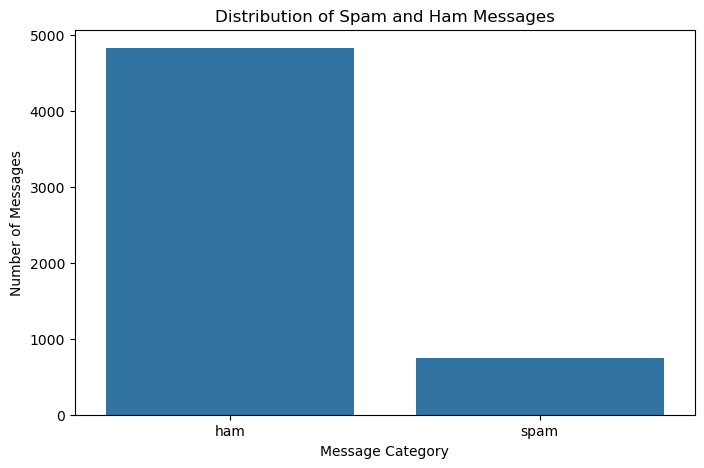

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='label')

plt.title('Distribution of Spam and Ham Messages')
plt.xlabel('Message Category')
plt.ylabel('Number of Messages')

plt.show()

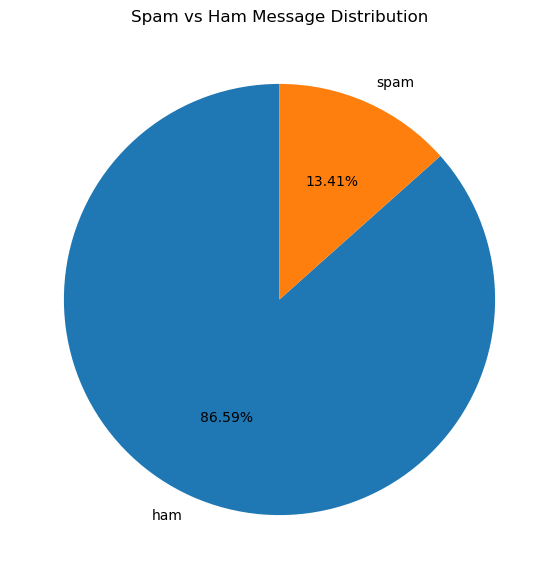

In [21]:
plt.figure(figsize=(7, 7))

plt.pie(
    label_counts,
    labels=label_counts.index,
    autopct='%1.2f%%',
    startangle=90
)

plt.title('Spam vs Ham Message Distribution')
plt.show()

In [23]:
# Calculate the length of each message

df['message_length'] = df['message'].apply(len)

df[['label', 'message', 'message_length']].head(10)

,label,message,message_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61
5,spam,FreeMsg Hey there darling it's been 3 week's n...,147
6,ham,Even my brother is not like to speak with me. ...,77
7,ham,As per your request 'Melle Melle (Oru Minnamin...,160
8,spam,WINNER!! As a valued network customer you have...,157
9,spam,Had your mobile 11 months or more? U R entitle...,154


In [25]:
# Message length statistics

df.groupby('label')['message_length'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4825.0,71.482487,58.440652,2.0,33.0,52.0,93.0,910.0
spam,747.0,138.670683,28.873603,13.0,133.0,149.0,157.0,223.0


In [27]:
# Average message length by category

avg_length = df.groupby('label')['message_length'].mean()

print(avg_length)

label
ham      71.482487
spam    138.670683
Name: message_length, dtype: float64


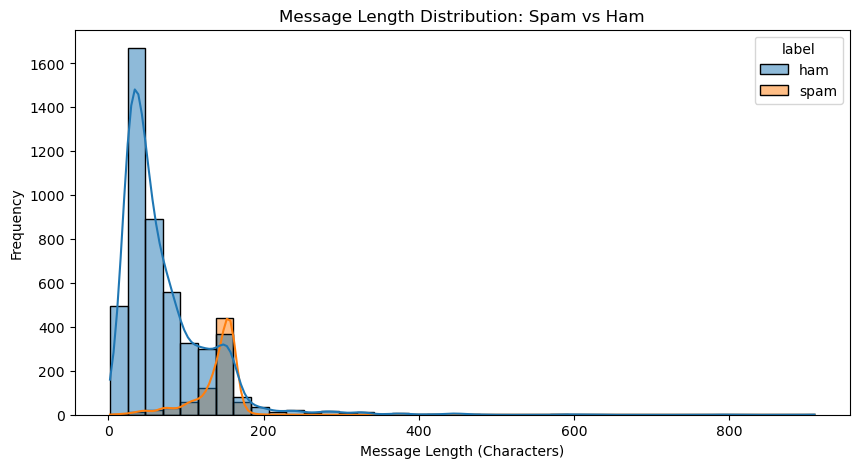

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='message_length',
    hue='label',
    bins=40,
    kde=True
)

plt.title('Message Length Distribution: Spam vs Ham')
plt.xlabel('Message Length (Characters)')
plt.ylabel('Frequency')

plt.show()

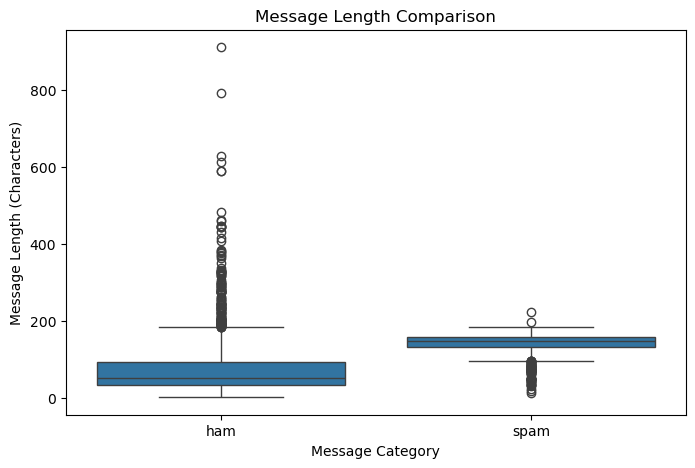

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='label',
    y='message_length'
)

plt.title('Message Length Comparison')
plt.xlabel('Message Category')
plt.ylabel('Message Length (Characters)')

plt.show()

In [33]:
from collections import Counter
from nltk.corpus import stopwords

nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

print("Text processing libraries ready!")

Text processing libraries ready!


[nltk_data] Downloading package stopwords to C:\Users\lubna
[nltk_data]     shireen\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [35]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z\s]', '', text)

    words = text.split()

    words = [
        word for word in words
        if word not in stop_words
    ]

    return words

df['cleaned_message'] = df['message'].apply(clean_text)

df[['message', 'cleaned_message']].head(10)

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only ...","[go, jurong, point, crazy, available, bugis, n..."
1,Ok lar... Joking wif u oni...,"[ok, lar, joking, wif, u, oni]"
2,Free entry in 2 a wkly comp to win FA Cup fina...,"[free, entry, wkly, comp, win, fa, cup, final,..."
3,U dun say so early hor... U c already then say...,"[u, dun, say, early, hor, u, c, already, say]"
4,"Nah I don't think he goes to usf, he lives aro...","[nah, dont, think, goes, usf, lives, around, t..."
5,FreeMsg Hey there darling it's been 3 week's n...,"[freemsg, hey, darling, weeks, word, back, id,..."
6,Even my brother is not like to speak with me. ...,"[even, brother, like, speak, treat, like, aids..."
7,As per your request 'Melle Melle (Oru Minnamin...,"[per, request, melle, melle, oru, minnaminungi..."
8,WINNER!! As a valued network customer you have...,"[winner, valued, network, customer, selected, ..."
9,Had your mobile 11 months or more? U R entitle...,"[mobile, months, u, r, entitled, update, lates..."


In [37]:
spam_words = ' '.join(
    df[df['label'] == 'spam']['cleaned_message'].apply(
        lambda words: ' '.join(words)
    )
)

spam_counter = Counter(spam_words.split())

spam_counter.most_common(20)

[('call', 350),
 ('free', 219),
 ('u', 155),
 ('txt', 151),
 ('ur', 144),
 ('mobile', 124),
 ('text', 121),
 ('stop', 118),
 ('claim', 113),
 ('reply', 101),
 ('prize', 92),
 ('get', 83),
 ('p', 73),
 ('nokia', 69),
 ('new', 69),
 ('send', 68),
 ('urgent', 63),
 ('cash', 62),
 ('win', 61),
 ('contact', 56)]

In [39]:
ham_words = ' '.join(
    df[df['label'] == 'ham']['cleaned_message'].apply(
        lambda words: ' '.join(words)
    )
)

ham_counter = Counter(ham_words.split())

ham_counter.most_common(20)

[('u', 1001),
 ('im', 463),
 ('get', 307),
 ('dont', 276),
 ('ltgt', 276),
 ('ok', 273),
 ('go', 252),
 ('ur', 246),
 ('ill', 242),
 ('got', 233),
 ('know', 232),
 ('like', 231),
 ('call', 231),
 ('come', 227),
 ('good', 224),
 ('day', 192),
 ('love', 190),
 ('time', 189),
 ('going', 167),
 ('want', 164)]

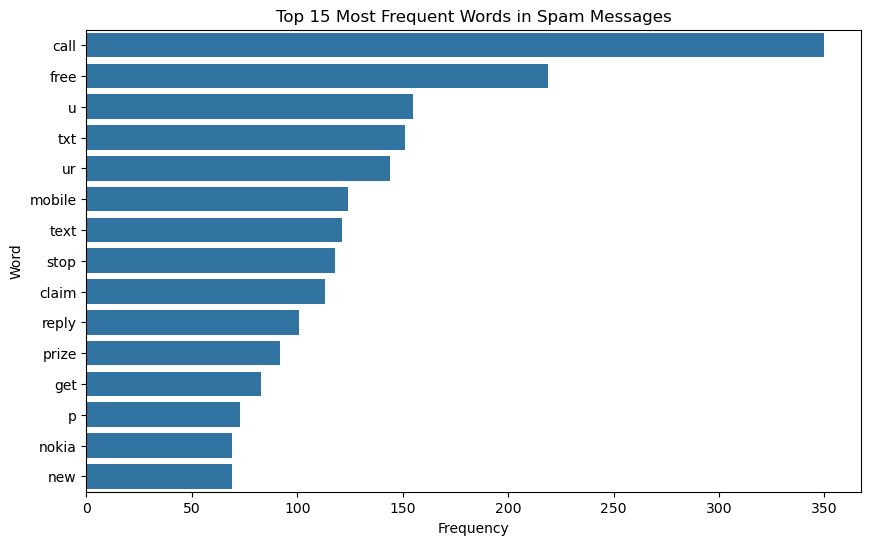

In [41]:
spam_top = pd.DataFrame(
    spam_counter.most_common(15),
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=spam_top,
    x='Frequency',
    y='Word'
)

plt.title('Top 15 Most Frequent Words in Spam Messages')
plt.show()

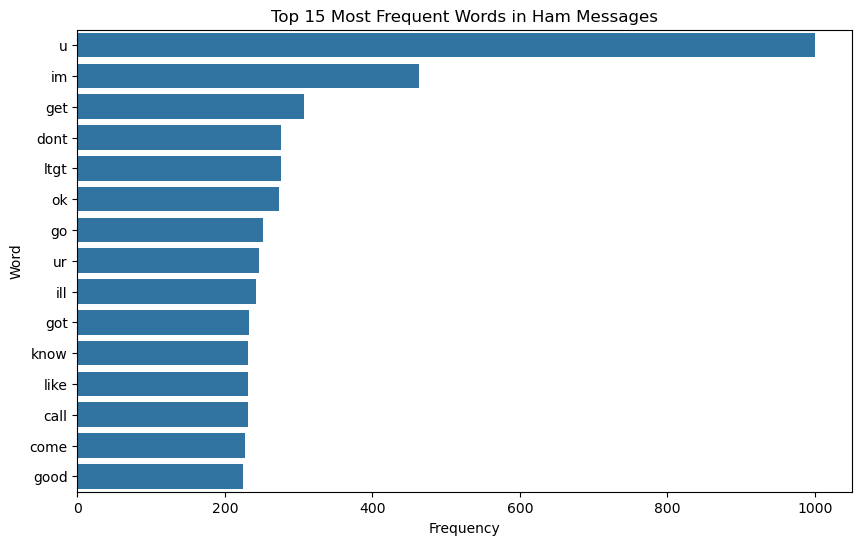

In [43]:
ham_top = pd.DataFrame(
    ham_counter.most_common(15),
    columns=['Word', 'Frequency']
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=ham_top,
    x='Frequency',
    y='Word'
)

plt.title('Top 15 Most Frequent Words in Ham Messages')
plt.show()

In [45]:
import nltk

from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))

print("NLP tools initialized successfully!")


[nltk_data] Downloading package punkt to C:\Users\lubna
[nltk_data]     shireen\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to C:\Users\lubna
[nltk_data]     shireen\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


NLP tools initialized successfully!


[nltk_data] Downloading package stopwords to C:\Users\lubna
[nltk_data]     shireen\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [47]:
def preprocess_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenization
    words = word_tokenize(text)

    # Remove stopwords and apply stemming
    words = [
        stemmer.stem(word)
        for word in words
        if word not in stop_words and len(word) > 1
    ]

    return ' '.join(words)


print("Preprocessing function created!")

Preprocessing function created!


In [49]:
df['processed_message'] = df['message'].apply(preprocess_text)

df[['message', 'processed_message']].head(10)

,message,processed_message
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi great world l...
1,Ok lar... Joking wif u oni...,ok lar joke wif oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri wkli comp win fa cup final tkt st m...
3,U dun say so early hor... U c already then say...,dun say earli hor alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darl week word back like fun still...
6,Even my brother is not like to speak with me. ...,even brother like speak treat like aid patent
7,As per your request 'Melle Melle (Oru Minnamin...,per request mell mell oru minnaminungint nurun...
8,WINNER!! As a valued network customer you have...,winner valu network custom select receivea pri...
9,Had your mobile 11 months or more? U R entitle...,mobil month entitl updat latest colour mobil c...


In [51]:
for i in range(5):
    print("Original Message:", df['message'].iloc[i])
    print("Processed Message:", df['processed_message'].iloc[i])
    print("-" * 80)

Original Message: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
Processed Message: go jurong point crazi avail bugi great world la buffet cine got amor wat
--------------------------------------------------------------------------------
Original Message: Ok lar... Joking wif u oni...
Processed Message: ok lar joke wif oni
--------------------------------------------------------------------------------
Original Message: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Processed Message: free entri wkli comp win fa cup final tkt st may text fa receiv entri question std txt rate appli
--------------------------------------------------------------------------------
Original Message: U dun say so early hor... U c already then say...
Processed Message: dun say earli hor alreadi say
----------------------------------------

In [53]:
empty_messages = (df['processed_message'].str.strip() == '').sum()

print("Empty processed messages:", empty_messages)

Empty processed messages: 13


In [55]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X = tfidf.fit_transform(df['processed_message'])

print("TF-IDF transformation completed!")
print("Feature matrix shape:", X.shape)

TF-IDF transformation completed!
Feature matrix shape: (5572, 5000)


In [57]:
print("Number of messages:", X.shape[0])
print("Number of features:", X.shape[1])
print("Matrix type:", type(X))

Number of messages: 5572
Number of features: 5000
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [59]:
feature_names = tfidf.get_feature_names_out()

tfidf_df = pd.DataFrame(
    X[:5].toarray(),
    columns=feature_names
)

tfidf_df.iloc[:, :20]

,aah,aathi,aathi dear,aathi love,abi,abiola,abl,abl come,abl deliv,abl get,abl pay,abt,abta,abta complimentari,ac,acc,accept,accept brother,accept day,access
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [61]:
# Convert categorical labels into numerical values

df['label_encoded'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

y = df['label_encoded']

print("Target variable encoded successfully!")
print(y.value_counts())

Target variable encoded successfully!
label_encoded
0    4825
1     747
Name: count, dtype: int64


In [63]:
df[['label', 'label_encoded']].head(10)

,label,label_encoded
0,ham,0
1,ham,0
2,spam,1
3,ham,0
4,ham,0
5,spam,1
6,ham,0
7,ham,0
8,spam,1
9,spam,1


In [65]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and testing split completed!")

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training and testing split completed!
Training samples: 4457
Testing samples: 1115


In [67]:
print("Training distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training distribution:
label_encoded
0    3859
1     598
Name: count, dtype: int64

Testing distribution:
label_encoded
0    966
1    149
Name: count, dtype: int64


In [69]:
# Initialize Naive Bayes model

nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train, y_train)

# Predict test data
nb_predictions = nb_model.predict(X_test)

print("Naive Bayes Model trained successfully!")

Naive Bayes Model trained successfully!


In [71]:
# Initialize Logistic Regression

lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

# Predict test data
lr_predictions = lr_model.predict(X_test)

print("Logistic Regression Model trained successfully!")


Logistic Regression Model trained successfully!


In [73]:
# Initialize SVM model

svm_model = LinearSVC()

# Train the model
svm_model.fit(X_train, y_train)

# Predict test data
svm_predictions = svm_model.predict(X_test)

print("SVM Model trained successfully!")

SVM Model trained successfully!


In [75]:
print("Actual Labels:")
print(y_test.iloc[:10].values)

print("\nNaive Bayes Predictions:")
print(nb_predictions[:10])

print("\nLogistic Regression Predictions:")
print(lr_predictions[:10])

print("\nSVM Predictions:")
print(svm_predictions[:10])

Actual Labels:
[0 0 0 1 0 0 0 0 0 0]

Naive Bayes Predictions:
[0 0 0 1 0 0 0 0 0 0]

Logistic Regression Predictions:
[0 0 0 1 0 0 0 0 0 0]

SVM Predictions:
[0 0 0 1 0 0 0 0 0 0]


In [77]:
# Split processed text before vectorization

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['processed_message'],
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit TF-IDF only on training messages
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Leakage-free TF-IDF transformation completed!")
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Leakage-free TF-IDF transformation completed!
Training shape: (4457, 5000)
Testing shape: (1115, 5000)


In [79]:
# Train Naive Bayes
nb_model.fit(X_train, y_train)

# Train Logistic Regression
lr_model.fit(X_train, y_train)

# Train SVM
svm_model.fit(X_train, y_train)

# Generate predictions
nb_predictions = nb_model.predict(X_test)
lr_predictions = lr_model.predict(X_test)
svm_predictions = svm_model.predict(X_test)

print("All three models retrained successfully!")

All three models retrained successfully!


In [81]:
def evaluate_model(y_true, y_pred, model_name):

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 Score': f1_score(y_true, y_pred)
    }

In [84]:
results = []

results.append(
    evaluate_model(y_test, nb_predictions, 'Naive Bayes')
)

results.append(
    evaluate_model(y_test, lr_predictions, 'Logistic Regression')
)

results.append(
    evaluate_model(y_test, svm_predictions, 'SVM')
)

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,0.971300,1.000000,0.785235,0.879699
1,Logistic Regression,0.969507,1.000000,0.771812,0.871212
2,SVM,0.983857,0.971223,0.906040,0.937500


In [86]:
metrics_df = results_df.copy()

for column in ['Accuracy', 'Precision', 'Recall', 'F1 Score']:
    metrics_df[column] = (
        metrics_df[column] * 100
    ).round(2)

metrics_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,97.13,100.00,78.52,87.97
1,Logistic Regression,96.95,100.00,77.18,87.12
2,SVM,98.39,97.12,90.60,93.75


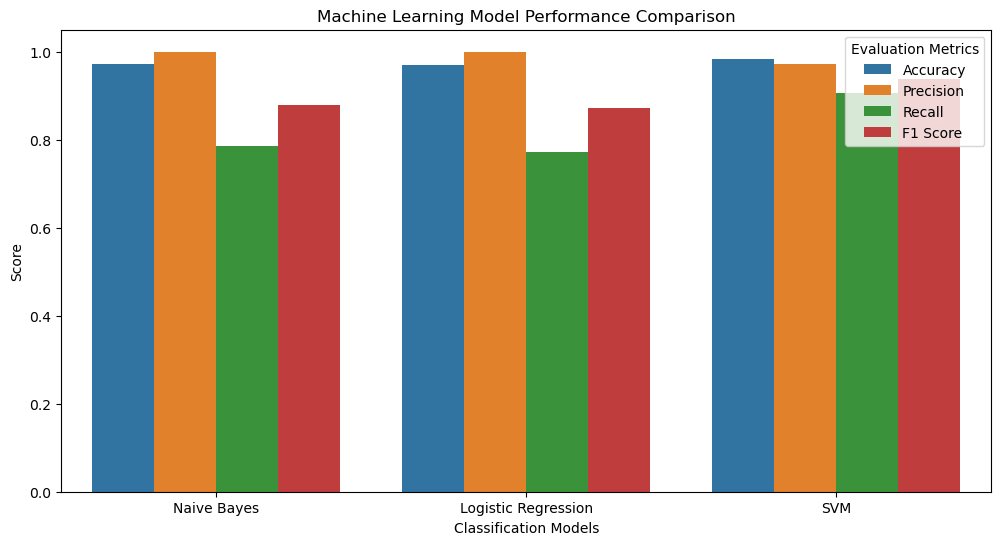

In [88]:
metrics_long = results_df.melt(
    id_vars='Model',
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=metrics_long,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title('Machine Learning Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xlabel('Classification Models')

plt.legend(title='Evaluation Metrics')
plt.show()

In [90]:
best_model = results_df.loc[
    results_df['F1 Score'].idxmax()
]

print("Best Performing Model:")
print(best_model)

Best Performing Model:
Model             SVM
Accuracy     0.983857
Precision    0.971223
Recall        0.90604
F1 Score       0.9375
Name: 2, dtype: object


In [92]:
# Generate confusion matrices

nb_cm = confusion_matrix(y_test, nb_predictions)
lr_cm = confusion_matrix(y_test, lr_predictions)
svm_cm = confusion_matrix(y_test, svm_predictions)

print("Naive Bayes Confusion Matrix:")
print(nb_cm)

print("\nLogistic Regression Confusion Matrix:")
print(lr_cm)

print("\nSVM Confusion Matrix:")
print(svm_cm)

Naive Bayes Confusion Matrix:
[[966   0]
 [ 32 117]]

Logistic Regression Confusion Matrix:
[[966   0]
 [ 34 115]]

SVM Confusion Matrix:
[[962   4]
 [ 14 135]]


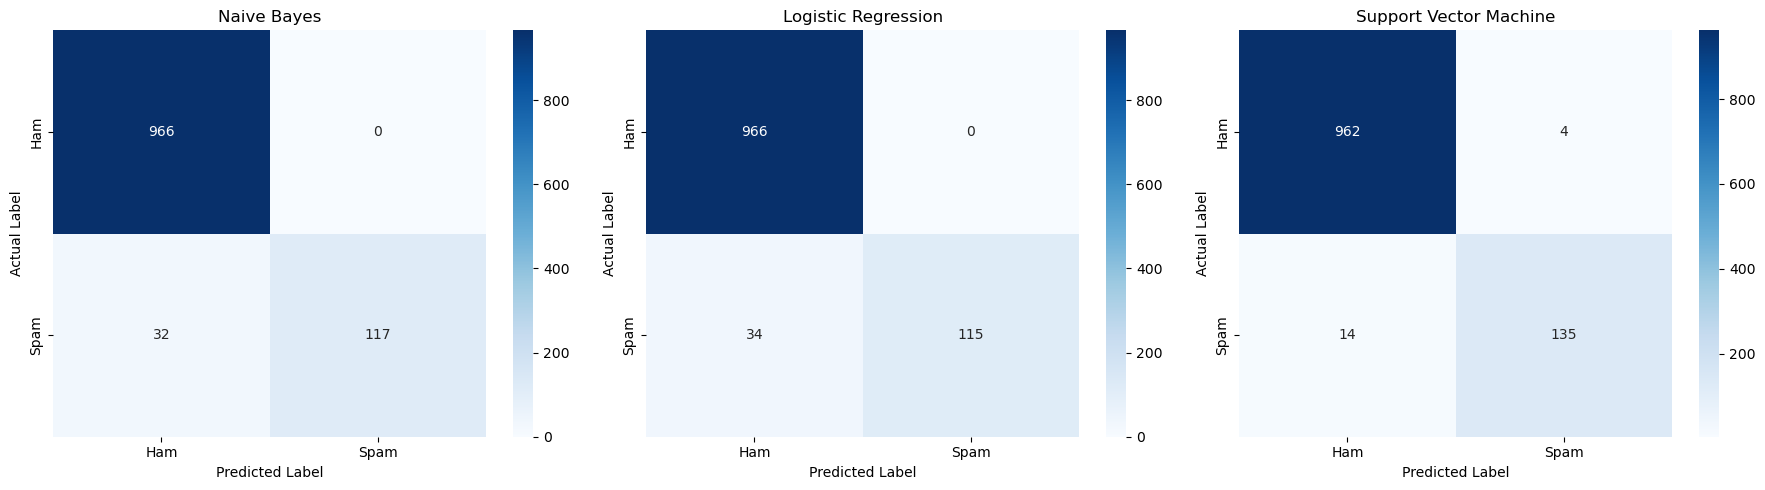

In [94]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

confusion_matrices = [
    (nb_cm, "Naive Bayes"),
    (lr_cm, "Logistic Regression"),
    (svm_cm, "Support Vector Machine")
]

for ax, (cm, title) in zip(axes, confusion_matrices):

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Ham', 'Spam'],
        yticklabels=['Ham', 'Spam'],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('Actual Label')

plt.tight_layout()
plt.show()

In [96]:
print("NAIVE BAYES CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    nb_predictions,
    target_names=['Ham', 'Spam']
))

print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    lr_predictions,
    target_names=['Ham', 'Spam']
))

print("\nSVM CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    svm_predictions,
    target_names=['Ham', 'Spam']
))


NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       1.00      0.79      0.88       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.98       966
        Spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.89      0.93      1115
weighted avg       0.97      0.97      0.97      1115


SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       966
        Spam       0.97      0.91      0.94       149

    accuracy                           0.98      1115
   macro avg       0.98 

In [98]:
# Select the best model based on F1-score

best_model_name = results_df.loc[
    results_df['F1 Score'].idxmax(), 'Model'
]

model_dict = {
    'Naive Bayes': nb_model,
    'Logistic Regression': lr_model,
    'SVM': svm_model
}

best_model = model_dict[best_model_name]

print("Selected Model:", best_model_name)

Selected Model: SVM


In [100]:
def predict_message(message):

    # Preprocess the input message
    processed = preprocess_text(message)

    # Convert message into TF-IDF features
    vectorized = tfidf.transform([processed])

    # Predict the category
    prediction = best_model.predict(vectorized)[0]

    if prediction == 1:
        return "SPAM"
    else:
        return "HAM (LEGITIMATE)"

In [102]:
test_messages = [
    "Congratulations! You have won a free iPhone. Claim now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! You have won a cash prize. Call now!",
    "Please send me the assignment notes."
]

for message in test_messages:

    result = predict_message(message)

    print("Message:", message)
    print("Prediction:", result)
    print("-" * 70)

Message: Congratulations! You have won a free iPhone. Claim now!
Prediction: SPAM
----------------------------------------------------------------------
Message: Hey, are we meeting for lunch today?
Prediction: HAM (LEGITIMATE)
----------------------------------------------------------------------
Message: URGENT! You have won a cash prize. Call now!
Prediction: SPAM
----------------------------------------------------------------------
Message: Please send me the assignment notes.
Prediction: HAM (LEGITIMATE)
----------------------------------------------------------------------


In [104]:
user_message = input("Enter a message to check: ")

prediction = predict_message(user_message)

print("\nPrediction:", prediction)

Enter a message to check:  Congratulations! You have won a free MacBook Pro. Claim your free prize asap!



Prediction: SPAM


In [106]:
user_message = input("Enter a message to check: ")

prediction = predict_message(user_message)

print("\nPrediction:", prediction)

Enter a message to check:  Congratulations! You have been selected for the next round of the interview! You next round details will be sent soon. All The Best!



Prediction: HAM (LEGITIMATE)


In [108]:
import joblib
import os

print("Joblib imported successfully!")

Joblib imported successfully!


In [110]:
os.makedirs("models", exist_ok=True)

print("Models folder created successfully!")

Models folder created successfully!


In [112]:
joblib.dump(best_model, "models/spam_detection_model.pkl")

print("Machine Learning model saved successfully!")

Machine Learning model saved successfully!


In [114]:
joblib.dump(tfidf, "models/tfidf_vectorizer.pkl")

print("TF-IDF vectorizer saved successfully!")

TF-IDF vectorizer saved successfully!


In [116]:
print("Saved model files:")

print(os.listdir("models"))

Saved model files:
['spam_detection_model.pkl', 'tfidf_vectorizer.pkl']
